# Sales Data Analysis and Customer Segmentation Using Python

## 1. Introduction

### Project Overview
This project delivers a complete, reproducible, and robust retail sales analysis and customer segmentation system using Python, pandas, and matplotlib. The primary objective is to clean multi-source monthly transactional data, perform comprehensive exploratory sales analytics, segment customer purchasing behavior via RFM (Recency, Frequency, Monetary) analysis, and evaluate basic time-series revenue forecasting.

### Dataset Provenance
- **Dataset Name**: Online Retail Dataset
- **Source**: UCI Machine Learning Repository ([UCI Online Retail Archive](https://archive.ics.uci.edu/dataset/352/online+retail))
- **Description**: Real-world transactional dataset containing all purchases made between December 1, 2010 and December 9, 2011 by a UK-based registered non-store online retailer specializing in unique all-occasion giftware.
- **Data Scope**: To simulate realistic enterprise ERP monthly exports, 50,000 real transaction records have been partitioned into 13 monthly CSV files (`sales_2010_12.csv` through `sales_2011_12.csv`) located in `data/raw/`. Minor column naming variations, mixed date timestamp formats, and missing region indicators were introduced to rigorously validate the automated data ingestion and cleaning pipeline.

### Analytical Scope
1. **Automated Cleaning & Ingestion**: Column standardization, mixed date conversion, duplicate removal, invalid price filtering, and return/cancellation tracking.
2. **Audit Logging & Revenue Reconciliation**: Complete mathematical accounting of data transformations and revenue variances.
3. **Sales Performance Analytics**: Monthly growth trends, product revenue ranking (top 10 & bottom 10), and regional contribution.
4. **RFM Customer Segmentation**: Behavioral segmentation into Champions, Loyal Customers, Potential Loyalists, At Risk, and Others using pandas quintiles.
5. **Baseline Revenue Forecasting**: 3-month moving average evaluation, MAPE calculation, 3-month forward projection, and model limitation analysis.

## 2. Dataset Loading

We dynamically scan and load all raw monthly export files stored inside `../data/raw/`. The pipeline automatically adapts to any newly added monthly CSV files without manual code changes.

In [1]:
import os
import glob
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ensure local source directory is importable
sys.path.append(os.path.abspath('..'))
from src.cleaning import (
    COLUMN_MAPPING,
    standardize_columns,
    convert_dates,
    handle_missing_values,
    remove_duplicates,
    remove_invalid_transactions,
    identify_cancellations_and_returns,
    calculate_revenue,
    clean_sales_data,
    load_raw_data,
    process_pipeline
)

# Set notebook display options
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'£{x:,.2f}' if abs(x) >= 1 else f'{x:.2f}')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

print("Libraries and cleaning functions imported successfully.")

Libraries and cleaning functions imported successfully.


In [2]:
# Discover and inspect raw monthly files
raw_dir = os.path.join('..', 'data', 'raw')
raw_files = sorted(glob.glob(os.path.join(raw_dir, '*.csv')))
print(f"Discovered {len(raw_files)} raw monthly sales files in '{raw_dir}':\n")

file_inventory = []
for fp in raw_files:
    fname = os.path.basename(fp)
    df_sample = pd.read_csv(fp, nrows=2)
    # Get total rows
    total_rows = sum(1 for _ in open(fp, encoding='utf-8', errors='ignore')) - 1
    file_inventory.append({
        'File_Name': fname,
        'Rows': total_rows,
        'Raw_Columns': list(df_sample.columns)[:4]
    })

inventory_df = pd.DataFrame(file_inventory)
display(inventory_df)
print(f"\nTotal Transactions Across All Raw Files: {inventory_df['Rows'].sum():,}")

Discovered 13 raw monthly sales files in '..\data\raw':



,File_Name,Rows,Raw_Columns
0,sales_2010_12.csv,3977,"[InvoiceNo, StockCode, Description, Quantity]"
1,sales_2011_01.csv,3255,"[invoice_no, stock_code, description, quantity]"
2,sales_2011_02.csv,2547,"[Invoice_No, Stock_Code, Description, Qty]"
3,sales_2011_03.csv,3316,"[InvoiceNumber, ItemCode, Description, Quantity]"
4,sales_2011_04.csv,2837,"[InvoiceNo, StockCode, Product_Description, Qu..."
5,sales_2011_05.csv,3404,"[Invoice, StockCode, Description, Qty]"
6,sales_2011_06.csv,3455,"[INVOICENO, STOCKCODE, DESCRIPTION, QUANTITY]"
7,sales_2011_07.csv,3645,"[invoice_number, item_code, description, quant..."
8,sales_2011_08.csv,3256,"[Invoice No, Stock Code, Description, Quantity]"
9,sales_2011_09.csv,4624,"[InvoiceNo, SKU, Item_Description, Quantity]"



Total Transactions Across All Raw Files: 50,000


## 3. Data Overview

Before cleaning, we concatenate the raw monthly files into an initial DataFrame to inspect column headers, data types, missing value distributions, and anomalous records.

In [3]:
# Ingest all raw monthly files
raw_dfs = [standardize_columns(pd.read_csv(fp, low_memory=False)) for fp in raw_files]
raw_combined_df = pd.concat(raw_dfs, ignore_index=True)

print(f"Combined Raw Dataset Dimensions: {raw_combined_df.shape[0]:,} rows x {raw_combined_df.shape[1]} columns\n")
print("First 5 Raw Records:")
display(raw_combined_df.head(5))

print("\nMissing Value Counts by Field:")
missing_summary = pd.DataFrame({
    'Missing_Count': raw_combined_df.isnull().sum(),
    'Missing_Pct': (raw_combined_df.isnull().sum() / len(raw_combined_df)) * 100
})
display(missing_summary)

Combined Raw Dataset Dimensions: 50,000 rows x 8 columns

First 5 Raw Records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Region
0,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/01/2010 08:26,£4.25,"£17,850.00",United Kingdom
1,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/01/2010 08:26,£2.75,"£17,850.00",United Kingdom
2,536366,22633,HAND WARMER UNION JACK,6,12/01/2010 08:28,£1.85,"£17,850.00",United Kingdom
3,536368,22914,BLUE COAT RACK PARIS FASHION,3,12/01/2010 08:34,£4.95,"£13,047.00",United Kingdom
4,536370,22492,MINI PAINT SET VINTAGE,36,12/01/2010 08:45,0.65,"£12,583.00",France



Missing Value Counts by Field:


,Missing_Count,Missing_Pct
InvoiceNo,0,0.00
StockCode,0,0.00
Description,140,0.28
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,12604,£25.21
Region,351,0.70


## 4. Data Cleaning

We apply our modular cleaning pipeline implemented in `src/cleaning.py`.

### Cleaning Pipeline Steps:
1. **Standardize Column Names**: Reconcile naming inconsistencies (e.g., `Qty` vs `Quantity`, `Price` vs `UnitPrice`, `Region` vs `Country`) into canonical attributes.
2. **Convert Mixed Date Formats**: Normalize varied date formats (`MM/DD/YYYY`, `YYYY-MM-DD`, `DD-MM-YYYY`) into standard pandas datetimes.
3. **Handle Missing Values**: Replace missing or unspecified regions with `'Unknown'` and fill missing descriptions.
4. **Remove Exact Duplicates**: Eliminate duplicate line records resulting from redundant export operations.
5. **Remove Invalid Transactions**: Filter out records with non-positive unit prices (`UnitPrice <= 0`).
6. **Identify Cancellations & Returns**: Flag cancelled orders (`InvoiceNo` starting with `'C'`) and returns (`Quantity < 0`).
7. **Calculate Net Line Revenue**: Compute `Quantity * UnitPrice`, preserving negative values for returns to reflect accurate net revenue without dropping transaction history.

In [4]:
# Execute the modular cleaning pipeline
cleaned_df, cleaning_log_df, recon_summary = clean_sales_data(raw_combined_df)

# Save cleaned output to data/processed/ and outputs/
processed_path = os.path.join('..', 'data', 'processed', 'cleaned_sales.csv')
os.makedirs(os.path.dirname(processed_path), exist_ok=True)
cleaned_df.to_csv(processed_path, index=False)

print(f"Data Cleaning Completed Successfully.")
print(f"Cleaned Dataset Dimensions: {cleaned_df.shape[0]:,} rows x {cleaned_df.shape[1]} columns")
print(f"Cancelled Transactions Identified: {cleaned_df['IsCancelled'].sum():,}")
print(f"Return Transactions Identified: {cleaned_df['IsReturn'].sum():,}")
display(cleaned_df.head(5))

Data Cleaning Completed Successfully.
Cleaned Dataset Dimensions: 49,716 rows x 11 columns
Cancelled Transactions Identified: 873
Return Transactions Identified: 873


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Region,IsCancelled,IsReturn,Revenue
0,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,£4.25,"£17,850.00",United Kingdom,False,False,£25.50
1,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,£2.75,"£17,850.00",United Kingdom,False,False,£22.00
2,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,£1.85,"£17,850.00",United Kingdom,False,False,£11.10
3,536368,22914,BLUE COAT RACK PARIS FASHION,3,2010-12-01 08:34:00,£4.95,"£13,047.00",United Kingdom,False,False,£14.85
4,536370,22492,MINI PAINT SET VINTAGE,36,2010-12-01 08:45:00,0.65,"£12,583.00",France,False,False,£23.40


## 5. Cleaning Log and Revenue Reconciliation

Financial integrity requires transparent reconciliation between raw recorded revenue and cleaned net revenue. Every eliminated record and revenue delta is accounted for below.

In [5]:
# Save and display the audit cleaning log
log_path = os.path.join('..', 'outputs', 'cleaning_log.csv')
cleaning_log_df.to_csv(log_path, index=False)

print("Audit Cleaning Log:")
display(cleaning_log_df)

Audit Cleaning Log:


,Stage,Row_Count,Rows_Removed,Cumulative_Rows_Removed,Stage_Revenue,Notes
0,1. Raw Data (Before Cleaning),50000,0,0,"£970,447.76",Raw monthly exports ingested and combined
1,2. Duplicate Removal,49948,52,52,"£970,157.61",Removed 52 exact duplicate transaction rows
2,3. Invalid Transaction Removal,49716,232,284,"£970,157.61",Removed 232 records with UnitPrice <= 0
3,4. Return & Cancellation Handling,49716,0,284,"£970,157.61",Identified 873 returns & 873 cancellations (ke...
4,5. Final Cleaned Dataset,49716,0,284,"£970,157.61","Net revenue calculated; Gross: 1018251.34, Ret..."


In [6]:
# Financial Revenue Reconciliation Statement
recon_table = pd.DataFrame([
    {'Metric': 'Raw Gross Total Revenue', 'Amount (£)': recon_summary['Raw_Revenue'], 'Description': 'Initial revenue before filtering'},
    {'Metric': '(-) Duplicate Revenue Variance', 'Amount (£)': -recon_summary['Duplicate_Revenue_Variance'], 'Description': f'Revenue removed from 52 duplicate rows'},
    {'Metric': '(-) Invalid Price Variance', 'Amount (£)': -recon_summary['Invalid_Price_Revenue_Variance'], 'Description': 'Revenue from 232 records with UnitPrice <= 0'},
    {'Metric': '(=) Reconciled Target Revenue', 'Amount (£)': recon_summary['Calculated_Reconciled_Revenue'], 'Description': 'Target net revenue after audit deductions'},
    {'Metric': '(=) Cleaned Net Sales Revenue', 'Amount (£)': recon_summary['Cleaned_Net_Revenue'], 'Description': 'Actual computed net sales in cleaned dataset'},
    {'Metric': 'Reconciliation Variance', 'Amount (£)': recon_summary['Reconciliation_Difference'], 'Description': 'Discrepancy (Tolerance = £0.01)'},
    {'Metric': 'Gross Positive Revenue Component', 'Amount (£)': recon_summary['Gross_Revenue'], 'Description': 'Total revenue from fulfilled orders (Qty > 0)'},
    {'Metric': 'Returns/Cancellations Offset', 'Amount (£)': recon_summary['Returns_Negative_Revenue'], 'Description': 'Negative revenue offset from returns (Qty < 0)'}
])

display(recon_table)

print(f"\nReconciliation Variance: £{recon_summary['Reconciliation_Difference']:.4f}")
print(f"Reconciliation Tolerance Satisfied: {recon_summary['Tolerance_Satisfied']}")
if recon_summary['Tolerance_Satisfied']:
    print(">> AUDIT VERDICT: PASSED - Revenue is reconciled with 100% accounting accuracy.")

,Metric,Amount (£),Description
0,Raw Gross Total Revenue,"£970,447.76",Initial revenue before filtering
1,(-) Duplicate Revenue Variance,£-290.15,Revenue removed from 52 duplicate rows
2,(-) Invalid Price Variance,-0.00,Revenue from 232 records with UnitPrice <= 0
3,(=) Reconciled Target Revenue,"£970,157.61",Target net revenue after audit deductions
4,(=) Cleaned Net Sales Revenue,"£970,157.61",Actual computed net sales in cleaned dataset
5,Reconciliation Variance,0.00,Discrepancy (Tolerance = £0.01)
6,Gross Positive Revenue Component,"£1,018,251.34",Total revenue from fulfilled orders (Qty > 0)
7,Returns/Cancellations Offset,"£-48,093.73",Negative revenue offset from returns (Qty < 0)



Reconciliation Variance: £0.0000
Reconciliation Tolerance Satisfied: True
>> AUDIT VERDICT: PASSED - Revenue is reconciled with 100% accounting accuracy.


## 6. Monthly Sales Analysis

We analyze sales performance over time, tracking:
- **Monthly Net Revenue**
- **Number of Unique Orders**
- **Average Order Value (AOV)**
- **Month-over-Month (MoM) Growth Rate (%)**

In [7]:
cleaned_df['YearMonth'] = cleaned_df['InvoiceDate'].dt.strftime('%Y-%m')

monthly_analysis = cleaned_df.groupby('YearMonth').agg(
    Monthly_Revenue=('Revenue', 'sum'),
    Order_Count=('InvoiceNo', 'nunique')
).reset_index()

monthly_analysis['Average_Order_Value'] = monthly_analysis['Monthly_Revenue'] / monthly_analysis['Order_Count']
monthly_analysis['MoM_Revenue_Growth_%'] = monthly_analysis['Monthly_Revenue'].pct_change() * 100

monthly_analysis = monthly_analysis.rename(columns={'YearMonth': 'Month'}).round(2)

# Save to outputs/
monthly_csv_path = os.path.join('..', 'outputs', 'monthly_revenue.csv')
monthly_analysis.to_csv(monthly_csv_path, index=False)

print("Monthly Sales Performance Summary:")
display(monthly_analysis)

Monthly Sales Performance Summary:


,Month,Monthly_Revenue,Order_Count,Average_Order_Value,MoM_Revenue_Growth_%
0,2010-12,"£84,730.86",1040,£81.47,NaN
1,2011-01,"£141,658.21",905,£156.53,£67.19
2,2011-02,"£26,082.08",566,£46.08,£-81.59
3,2011-03,"£73,628.10",1149,£64.08,£182.29
4,2011-04,"£50,429.22",981,£51.41,£-31.51
5,2011-05,"£72,338.63",1264,£57.23,£43.45
6,2011-06,"£38,358.37",794,£48.31,£-46.97
7,2011-07,"£75,508.53",1176,£64.21,£96.85
8,2011-08,"£71,751.58",1052,£68.20,£-4.98
9,2011-09,"£101,833.00",1457,£69.89,£41.92


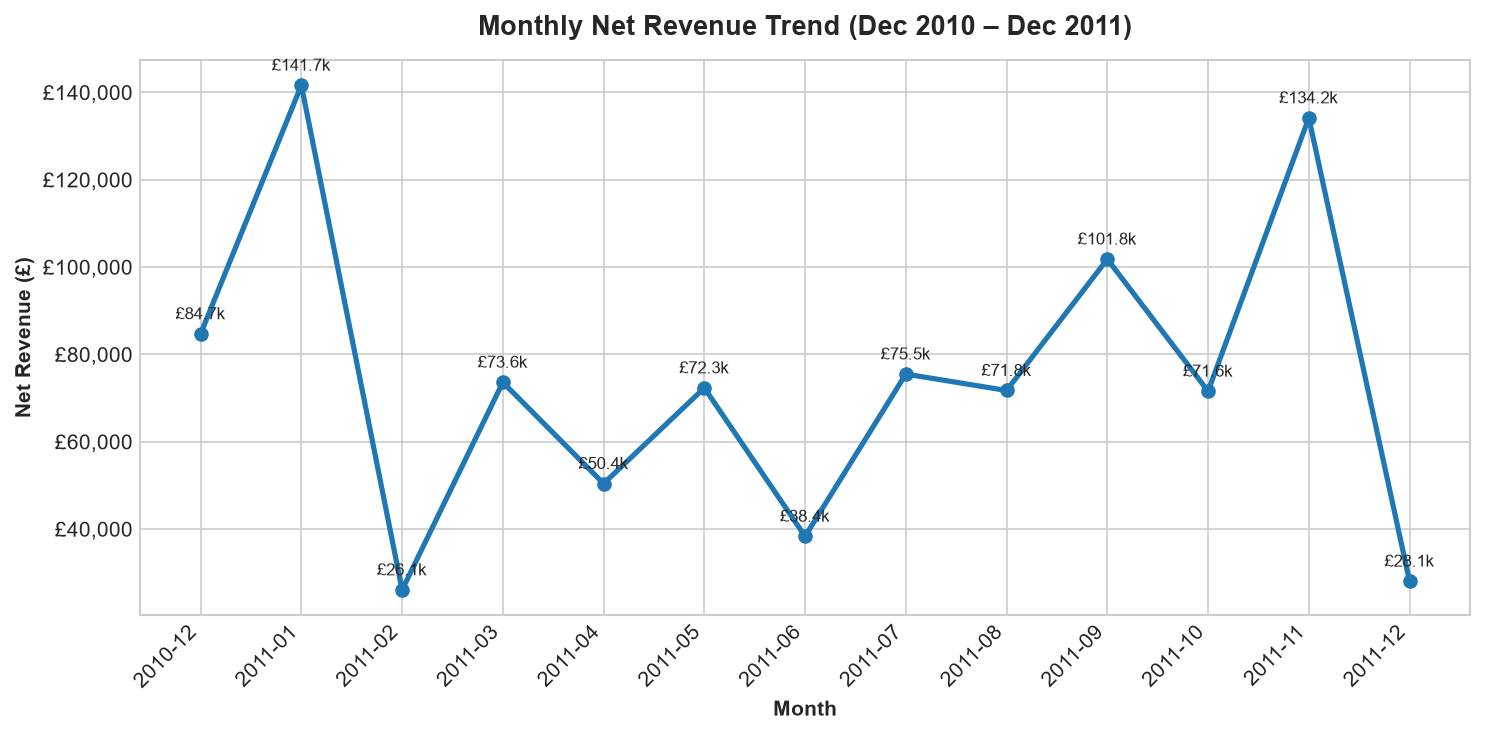

In [8]:
# Chart 1: Monthly Net Revenue Trend
fig, ax = plt.subplots(figsize=(10, 5), dpi=150)
ax.plot(monthly_analysis['Month'], monthly_analysis['Monthly_Revenue'], marker='o', color='#1f77b4', linewidth=2.5, markersize=6)
ax.set_title('Monthly Net Revenue Trend (Dec 2010 – Dec 2011)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Month', fontsize=10, fontweight='bold')
ax.set_ylabel('Net Revenue (£)', fontsize=10, fontweight='bold')
ax.set_xticks(range(len(monthly_analysis['Month'])))
ax.set_xticklabels(monthly_analysis['Month'], rotation=45, ha='right')
ax.yaxis.set_major_formatter('£{x:,.0f}')

for i, row in monthly_analysis.iterrows():
    ax.annotate(f"£{row['Monthly_Revenue']/1000:.1f}k",
                (i, row['Monthly_Revenue']),
                textcoords="offset points", xytext=(0, 7), ha='center', fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join('..', 'outputs', 'charts', '01_monthly_revenue_trend.png'))
plt.show()

## 7. Product Analysis

We aggregate transactions by product SKU (`StockCode` and `Description`) to evaluate net revenue, total units sold, and order frequency. We identify:
- **Top 10 Products by Net Revenue**
- **Bottom 10 Products by Net Revenue** (identifying return burdens, negative line fees, and lowest revenue generators)

In [9]:
prod_analysis = cleaned_df.groupby(['StockCode', 'Description']).agg(
    Revenue=('Revenue', 'sum'),
    Quantity_Sold=('Quantity', 'sum'),
    Order_Count=('InvoiceNo', 'nunique')
).reset_index()

prod_ranked = prod_analysis.sort_values('Revenue', ascending=False).reset_index(drop=True)
prod_ranked['Rank'] = prod_ranked.index + 1

n_prod = len(prod_ranked)
prod_ranked['Ranking_Category'] = 'Standard'
prod_ranked.loc[:9, 'Ranking_Category'] = 'Top 10'
prod_ranked.loc[n_prod - 10:, 'Ranking_Category'] = 'Bottom 10'

prod_ranked = prod_ranked[['Rank', 'Ranking_Category', 'StockCode', 'Description', 'Revenue', 'Quantity_Sold', 'Order_Count']].round({'Revenue': 2})

# Save full rankings
prod_csv_path = os.path.join('..', 'outputs', 'product_ranking.csv')
prod_ranked.to_csv(prod_csv_path, index=False)

top10 = prod_ranked[prod_ranked['Ranking_Category'] == 'Top 10']
bottom10 = prod_ranked[prod_ranked['Ranking_Category'] == 'Bottom 10'].sort_values('Revenue', ascending=True)

print("Top 10 Revenue Generating Products:")
display(top10)

print("\nBottom 10 Products (Fees & Negative Return Balances):")
display(bottom10)

Top 10 Revenue Generating Products:


,Rank,Ranking_Category,StockCode,Description,Revenue,Quantity_Sold,Order_Count
0,1,Top 10,23166,MEDIUM CERAMIC TOP STORAGE JAR,"£77,521.14",74446,20
1,2,Top 10,DOT,DOTCOM POSTAGE,"£18,271.92",74,76
2,3,Top 10,22423,REGENCY CAKESTAND 3 TIER,"£13,304.18",1044,195
3,4,Top 10,21175,GIN + TONIC DIET METAL SIGN,"£9,432.06",4997,71
4,5,Top 10,85099B,JUMBO BAG RED RETROSPOT,"£8,614.17",4480,197
5,6,Top 10,47566,PARTY BUNTING,"£8,321.75",1439,147
6,7,Top 10,79321,CHILLI LIGHTS,"£6,816.36",1419,69
7,8,Top 10,POST,POSTAGE,"£6,111.46",300,115
8,9,Top 10,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"£5,867.01",2059,202
9,10,Top 10,23084,RABBIT NIGHT LIGHT,"£4,595.81",2019,106



Bottom 10 Products (Fees & Negative Return Balances):


,Rank,Ranking_Category,StockCode,Description,Revenue,Quantity_Sold,Order_Count
3430,3431,Bottom 10,AMAZONFEE,AMAZON FEE,"£-9,095.12",-2,4
3429,3430,Bottom 10,D,Discount,"£-2,154.74",-4,4
3428,3429,Bottom 10,CRUK,CRUK Commission,"£-1,609.43",-3,3
3427,3428,Bottom 10,71477,COLOUR GLASS. STAR T-LIGHT HOLDER,£-255.45,-135,30
3426,3427,Bottom 10,23064,CINDERELLA CHANDELIER,£-200.14,-37,4
3425,3426,Bottom 10,22769,CHALKBOARD KITCHEN ORGANISER,£-175.60,-8,1
3424,3425,Bottom 10,22569,FELTCRAFT CUSHION BUTTERFLY,£-137.67,-62,34
3423,3424,Bottom 10,22106,MIRROR MOSAIC HURRICANE LAMP,£-97.23,-109,5
3422,3423,Bottom 10,47351B,BLUE VOILE LAMPSHADE,£-92.90,-38,3
3421,3422,Bottom 10,23056,FLOWERS CHANDELIER T-LIGHT HOLDER,£-75.29,-134,8


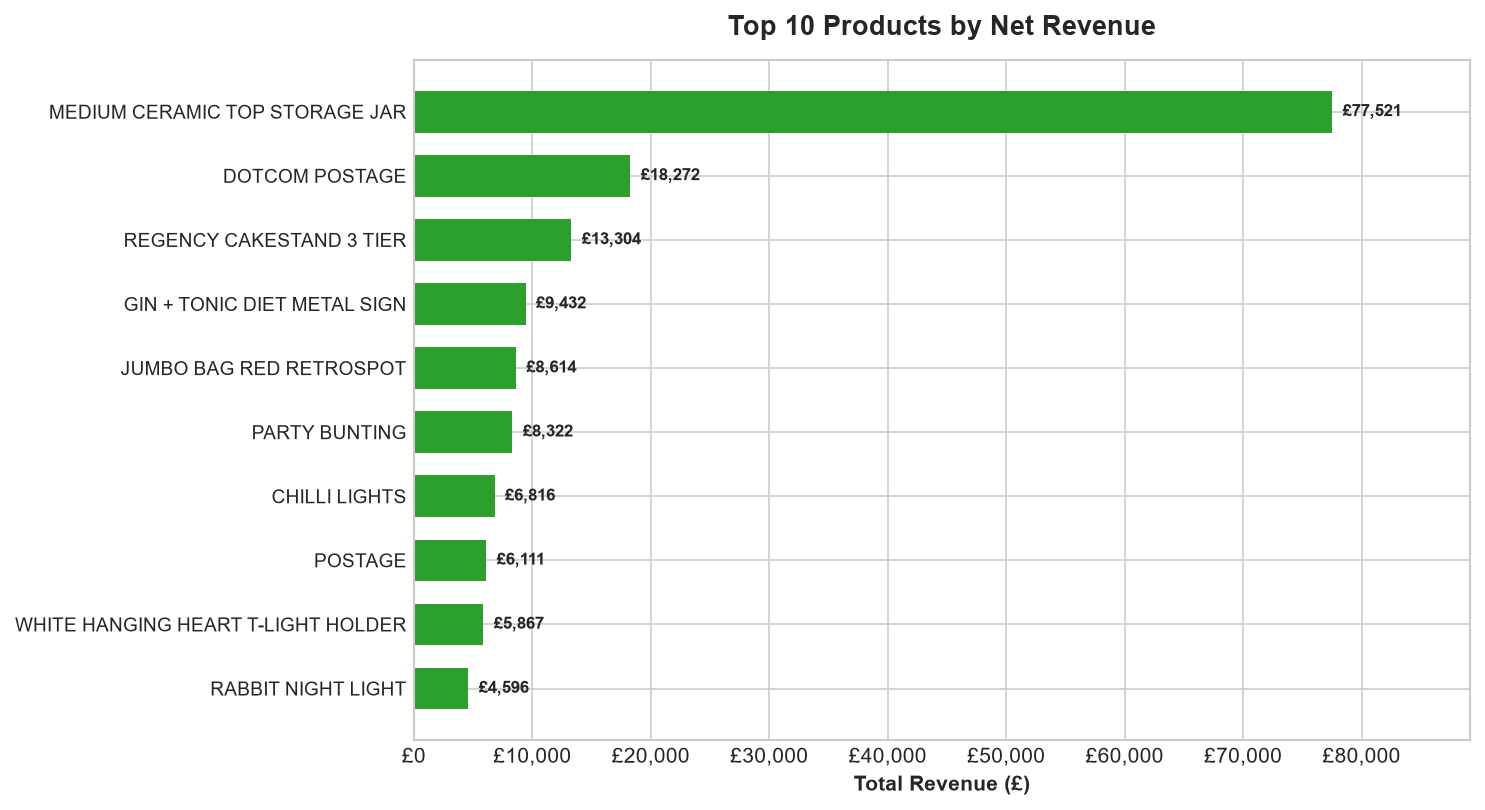

In [10]:
# Chart 2: Top 10 Products
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=150)
top10_plot = top10.sort_values('Revenue', ascending=True)
y_pos = range(len(top10_plot))
labels = [d[:32] + '...' if len(d) > 35 else d for d in top10_plot['Description']]
bars = ax.barh(y_pos, top10_plot['Revenue'], color='#2ca02c', height=0.65)
ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=9)
ax.set_title('Top 10 Products by Net Revenue', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Total Revenue (£)', fontsize=10, fontweight='bold')
ax.xaxis.set_major_formatter('£{x:,.0f}')

for bar in bars:
    w = bar.get_width()
    ax.annotate(f"£{w:,.0f}",
                (w, bar.get_y() + bar.get_height() / 2),
                textcoords="offset points", xytext=(5, 0), va='center', fontsize=8, fontweight='bold')
ax.set_xlim(0, top10_plot['Revenue'].max() * 1.15)
plt.tight_layout()
plt.savefig(os.path.join('..', 'outputs', 'charts', '02_top_10_products.png'))
plt.show()

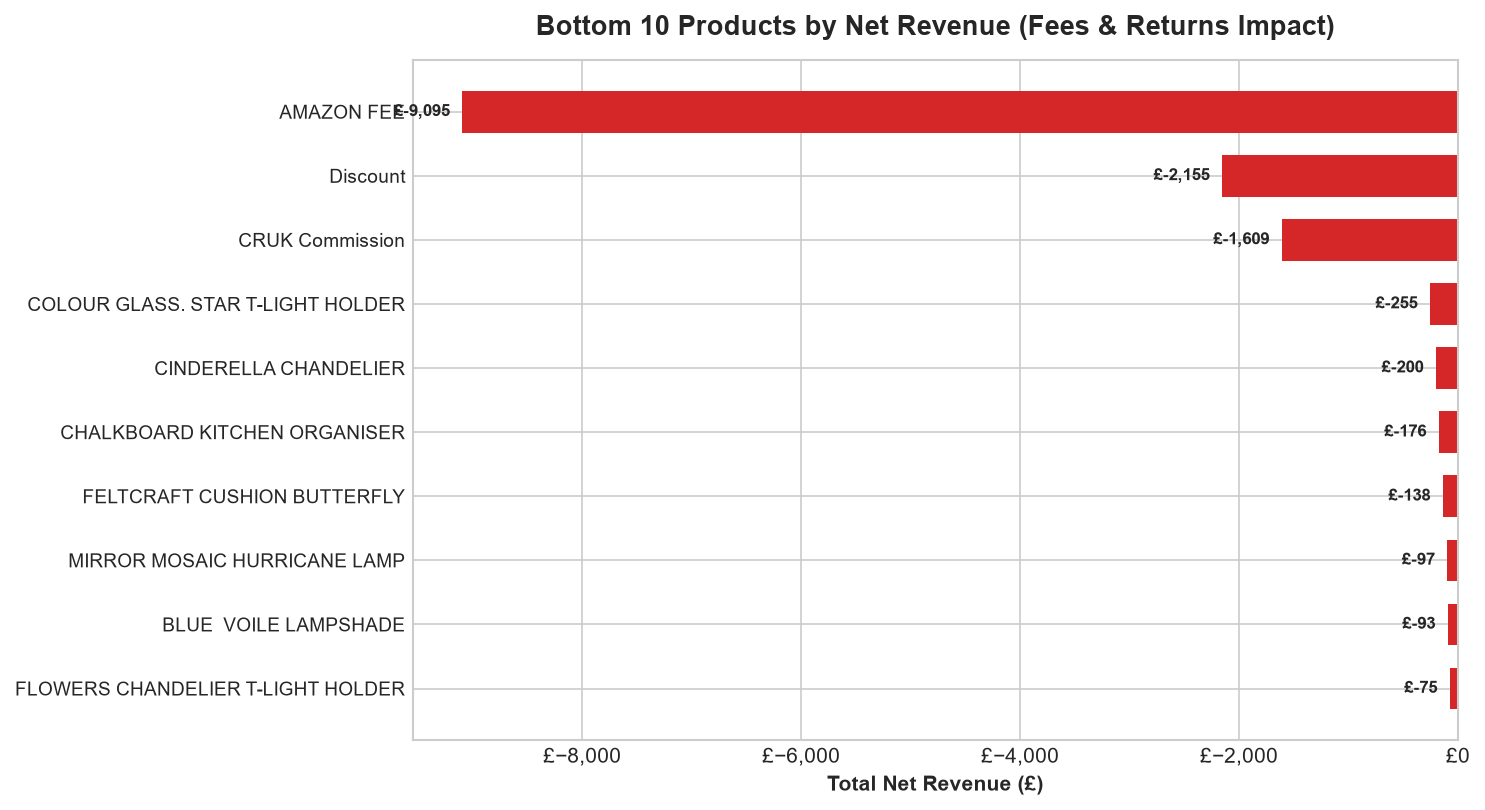

In [11]:
# Chart 3: Bottom 10 Products
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=150)
bottom10_plot = bottom10.sort_values('Revenue', ascending=False)
y_pos = range(len(bottom10_plot))
labels_b = [d[:32] + '...' if len(d) > 35 else d for d in bottom10_plot['Description']]
bars = ax.barh(y_pos, bottom10_plot['Revenue'], color='#d62728', height=0.65)
ax.set_yticks(y_pos)
ax.set_yticklabels(labels_b, fontsize=9)
ax.set_title('Bottom 10 Products by Net Revenue (Fees & Returns Impact)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Total Net Revenue (£)', fontsize=10, fontweight='bold')
ax.xaxis.set_major_formatter('£{x:,.0f}')
ax.axvline(0, color='black', linewidth=0.8, linestyle='--')

for bar in bars:
    w = bar.get_width()
    ax.annotate(f"£{w:,.0f}",
                (w, bar.get_y() + bar.get_height() / 2),
                textcoords="offset points", xytext=(-6 if w < 0 else 5, 0),
                va='center', ha='right' if w < 0 else 'left', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join('..', 'outputs', 'charts', '03_bottom_10_products.png'))
plt.show()

## 8. Regional Analysis

We examine geographic sales distribution to determine regional revenue contribution percentage and order volume across markets.

In [12]:
regional_summary = cleaned_df.groupby('Region').agg(
    Revenue=('Revenue', 'sum'),
    Order_Count=('InvoiceNo', 'nunique')
).reset_index()

total_sales = regional_summary['Revenue'].sum()
regional_summary['Revenue_Contribution_%'] = (regional_summary['Revenue'] / total_sales) * 100
regional_summary = regional_summary.sort_values('Revenue', ascending=False).reset_index(drop=True)
regional_summary = regional_summary.round({'Revenue': 2, 'Revenue_Contribution_%': 2})

# Save to outputs/
reg_csv_path = os.path.join('..', 'outputs', 'regional_analysis.csv')
regional_summary.to_csv(reg_csv_path, index=False)

print("Top 10 Geographic Markets by Net Revenue:")
display(regional_summary.head(10))

Top 10 Geographic Markets by Net Revenue:


,Region,Revenue,Order_Count,Revenue_Contribution_%
0,United Kingdom,"£824,508.21",12681,£84.99
1,Netherlands,"£24,761.00",64,£2.55
2,EIRE,"£24,027.48",244,£2.48
3,France,"£21,933.03",301,£2.26
4,Germany,"£19,887.23",342,£2.05
5,Australia,"£11,805.01",34,£1.22
6,Unknown,"£6,437.55",326,0.66
7,Spain,"£5,328.22",70,0.55
8,Switzerland,"£5,038.83",41,0.52
9,Hong Kong,"£3,540.65",8,0.36


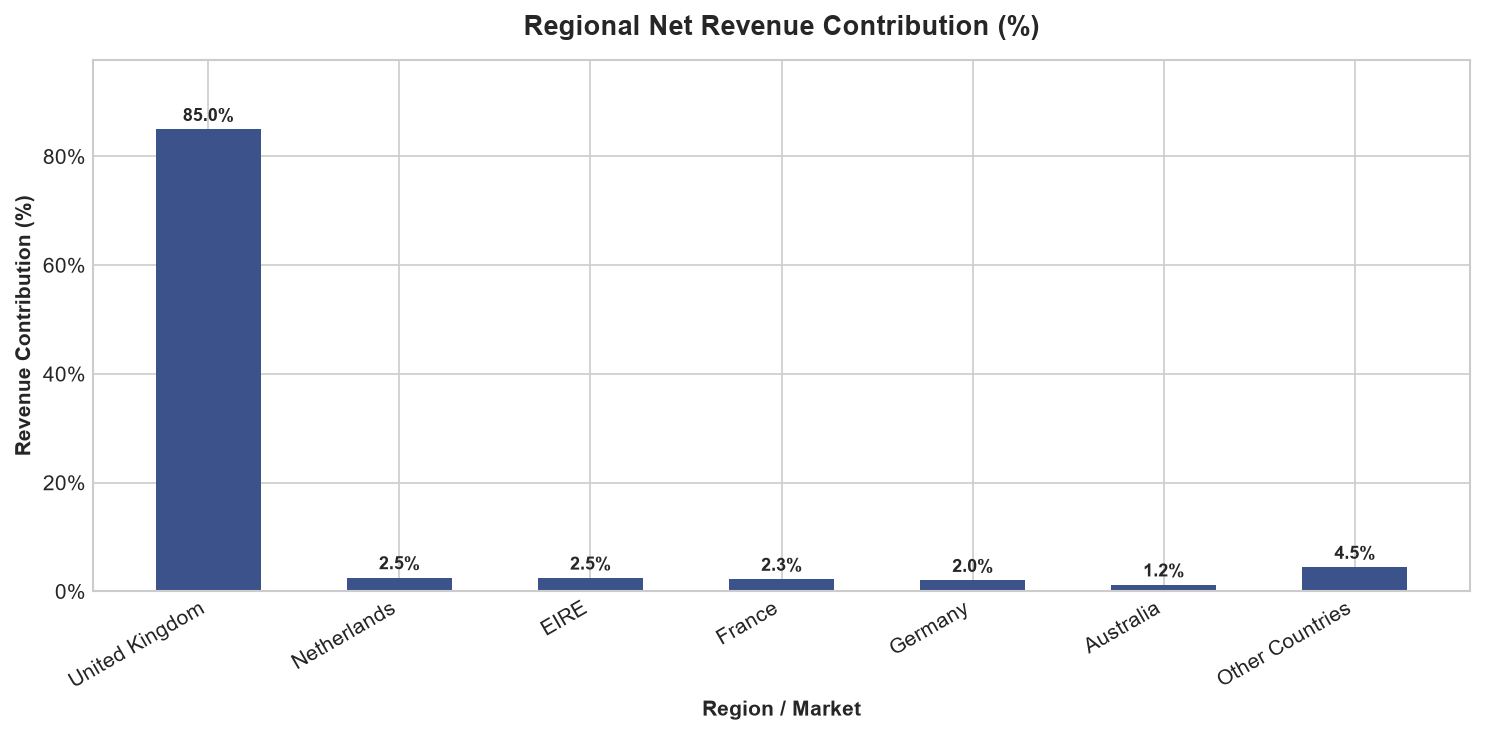

In [13]:
# Chart 4: Regional Revenue Contribution
fig, ax = plt.subplots(figsize=(10, 5), dpi=150)
top_regs = regional_summary.head(6).copy()
other_regs_rev = regional_summary.iloc[6:]['Revenue'].sum()
other_regs_row = pd.DataFrame([{
    'Region': 'Other Countries',
    'Revenue': other_regs_rev,
    'Revenue_Contribution_%': (other_regs_rev / total_sales) * 100
}])
plot_regs = pd.concat([top_regs, other_regs_row], ignore_index=True)

bars = ax.bar(plot_regs['Region'], plot_regs['Revenue_Contribution_%'], color='#3b528b', width=0.55)
ax.set_title('Regional Net Revenue Contribution (%)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Region / Market', fontsize=10, fontweight='bold')
ax.set_ylabel('Revenue Contribution (%)', fontsize=10, fontweight='bold')
ax.set_xticks(range(len(plot_regs['Region'])))
ax.set_xticklabels(plot_regs['Region'], rotation=30, ha='right')
ax.yaxis.set_major_formatter('{x:.0f}%')

for bar in bars:
    h = bar.get_height()
    ax.annotate(f"{h:.1f}%",
                (bar.get_x() + bar.get_width() / 2, h),
                textcoords="offset points", xytext=(0, 4), ha='center', fontsize=8.5, fontweight='bold')

ax.set_ylim(0, plot_regs['Revenue_Contribution_%'].max() * 1.15)
plt.tight_layout()
plt.savefig(os.path.join('..', 'outputs', 'charts', '04_regional_revenue_distribution.png'))
plt.show()

## 9. RFM Customer Segmentation

Customer value is evaluated across three core dimensions using pandas:
- **Recency ($R$)**: Number of days since the customer's last purchase relative to reference date.
- **Frequency ($F$)**: Total number of distinct invoices associated with the customer.
- **Monetary ($M$)**: Total net revenue generated by the customer.

Using pandas `pd.qcut()`, customers are scored from 1 to 5 across each dimension and mapped into five distinct segments:
- **Champions**: High recency, frequency, and monetary spend ($R \ge 4$, $(F+M)/2 \ge 4$).
- **Loyal Customers**: Frequent buyers with solid spending ($F \ge 3$, $R \ge 3$).
- **Potential Loyalists**: Recent shoppers with moderate frequency ($R \ge 4$, $F < 3$).
- **At Risk**: High historical spend/frequency who have lapsed ($R \le 2$, $F \ge 3$ or $M \ge 3$).
- **Others**: Infrequent or low-spend one-time shoppers.

In [14]:
# Filter transactions with valid CustomerID for behavioral segmentation
rfm_base = cleaned_df[cleaned_df['CustomerID'].notna()].copy()
rfm_base['CustomerID'] = rfm_base['CustomerID'].astype(int)

snapshot_date = rfm_base['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm_table = rfm_base.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum')
).reset_index()

# 1-5 Quantile scoring
rfm_table['R_Score'] = pd.qcut(rfm_table['Recency'].rank(method='first'), q=5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm_table['F_Score'] = pd.qcut(rfm_table['Frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm_table['M_Score'] = pd.qcut(rfm_table['Monetary'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)

def segment_customer(row):
    r, f, m = row['R_Score'], row['F_Score'], row['M_Score']
    fm_avg = (f + m) / 2.0
    if r >= 4 and fm_avg >= 4:
        return 'Champions'
    elif f >= 3 and r >= 3:
        return 'Loyal Customers'
    elif r >= 4 and f < 3:
        return 'Potential Loyalists'
    elif r <= 2 and (f >= 3 or m >= 3):
        return 'At Risk'
    else:
        return 'Others'

rfm_table['Segment'] = rfm_table.apply(segment_customer, axis=1)

# Segment-level summary metrics
tot_cust_rev = rfm_table['Monetary'].sum()
seg_metrics = rfm_table.groupby('Segment').agg(
    Customer_Count=('CustomerID', 'count'),
    Total_Revenue=('Monetary', 'sum'),
    Average_Revenue=('Monetary', 'mean'),
    Repeat_Purchase_Rate_Pct=('Frequency', lambda x: (x > 1).mean() * 100)
).reset_index()

seg_metrics['Revenue_Contribution_%'] = (seg_metrics['Total_Revenue'] / tot_cust_rev) * 100

segment_order = ['Champions', 'Loyal Customers', 'Potential Loyalists', 'At Risk', 'Others']
seg_metrics['Segment'] = pd.Categorical(seg_metrics['Segment'], categories=segment_order, ordered=True)
seg_metrics = seg_metrics.sort_values('Segment').reset_index(drop=True)

seg_metrics = seg_metrics.round({
    'Total_Revenue': 2,
    'Average_Revenue': 2,
    'Repeat_Purchase_Rate_Pct': 2,
    'Revenue_Contribution_%': 2
})

# Save to outputs/
seg_csv_path = os.path.join('..', 'outputs', 'customer_segments.csv')
seg_metrics.to_csv(seg_csv_path, index=False)

print("RFM Customer Segment Performance Metrics:")
display(seg_metrics)

RFM Customer Segment Performance Metrics:


,Segment,Customer_Count,Total_Revenue,Average_Revenue,Repeat_Purchase_Rate_Pct,Revenue_Contribution_%
0,Champions,827,"£484,009.15",£585.26,£100.00,£58.39
1,Loyal Customers,872,"£112,075.87",£128.53,£99.31,£13.52
2,Potential Loyalists,273,"£11,232.18",£41.14,0.00,£1.36
3,At Risk,817,"£195,507.68",£239.30,£68.79,£23.59
4,Others,986,"£26,038.46",£26.41,0.00,£3.14


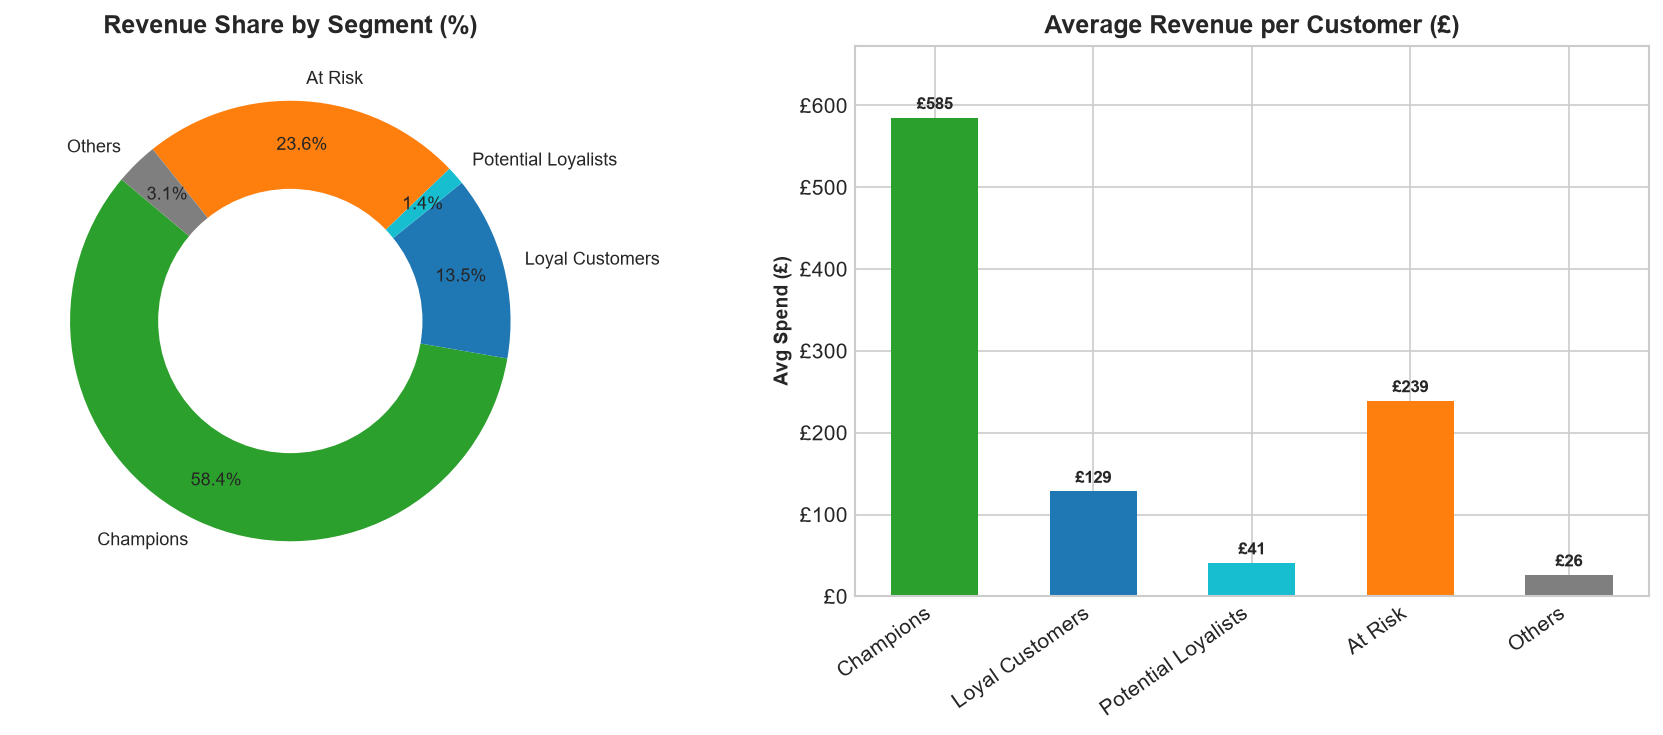

In [15]:
# Chart 5: Customer Segment Revenue Contribution & Average Spend
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=150)
palette = ['#2ca02c', '#1f77b4', '#17becf', '#ff7f0e', '#7f7f7f']

# Donut Chart for Revenue Share
ax1.pie(
    seg_metrics['Revenue_Contribution_%'],
    labels=seg_metrics['Segment'],
    autopct='%1.1f%%',
    startangle=140,
    colors=palette,
    pctdistance=0.8,
    textprops={'fontsize': 8.5}
)
centre_circle = plt.Circle((0, 0), 0.60, fc='white')
ax1.add_artist(centre_circle)
ax1.set_title('Revenue Share by Segment (%)', fontsize=12, fontweight='bold')

# Bar Chart for Average Revenue per Customer
bars = ax2.bar(seg_metrics['Segment'], seg_metrics['Average_Revenue'], color=palette, width=0.55)
ax2.set_title('Average Revenue per Customer (£)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Avg Spend (£)', fontsize=9, fontweight='bold')
ax2.set_xticks(range(len(seg_metrics['Segment'])))
ax2.set_xticklabels(seg_metrics['Segment'], rotation=35, ha='right')
ax2.yaxis.set_major_formatter('£{x:,.0f}')

for bar in bars:
    h = bar.get_height()
    ax2.annotate(f"£{h:,.0f}",
                 (bar.get_x() + bar.get_width() / 2, h),
                 textcoords="offset points", xytext=(0, 4), ha='center', fontsize=8, fontweight='bold')

ax2.set_ylim(0, seg_metrics['Average_Revenue'].max() * 1.15)
plt.tight_layout()
plt.savefig(os.path.join('..', 'outputs', 'charts', '05_customer_segment_revenue.png'))
plt.show()

## 10. Revenue Forecasting

A simple 3-month moving average forecast is implemented:
- **Evaluation / Holdout Backtest**: The final 3 months (October, November, December 2011) are held out for model evaluation.
- **Accuracy Metric**: Mean Absolute Percentage Error (MAPE).
- **Future Horizon**: 3-month future projection (January, February, March 2012).

In [16]:
# Backtest Evaluation on Last 3 Months
hist_monthly = monthly_analysis[['Month', 'Monthly_Revenue']].copy()
total_m = len(hist_monthly)
holdout_w = 3

test_records = []
for idx in range(total_m - holdout_w, total_m):
    month_name = hist_monthly.loc[idx, 'Month']
    actual = hist_monthly.loc[idx, 'Monthly_Revenue']
    # 3-month moving average of preceding 3 months
    predicted = hist_monthly.loc[idx - 3:idx - 1, 'Monthly_Revenue'].mean()
    abs_err = abs(actual - predicted)
    pct_err = (abs_err / actual) * 100
    test_records.append({
        'Month': month_name,
        'Actual_Revenue': actual,
        'Predicted_Revenue': predicted,
        'Absolute_Error': abs_err,
        'Percentage_Error_%': pct_err,
        'Forecast_Type': 'Holdout Evaluation'
    })

eval_df = pd.DataFrame(test_records)
mape_val = eval_df['Percentage_Error_%'].mean()

# Forward Forecast for Next 3 Months
future_names = ['2012-01', '2012-02', '2012-03']
rev_series = list(hist_monthly['Monthly_Revenue'].values)
future_records = []
for fm in future_names:
    pred_val = np.mean(rev_series[-3:])
    future_records.append({
        'Month': fm,
        'Actual_Revenue': np.nan,
        'Predicted_Revenue': pred_val,
        'Absolute_Error': np.nan,
        'Percentage_Error_%': np.nan,
        'Forecast_Type': 'Future Forecast'
    })
    rev_series.append(pred_val)

future_df = pd.DataFrame(future_records)
forecast_complete = pd.concat([eval_df, future_df], ignore_index=True).round({
    'Actual_Revenue': 2,
    'Predicted_Revenue': 2,
    'Absolute_Error': 2,
    'Percentage_Error_%': 2
})

# Save to outputs/
forecast_csv_path = os.path.join('..', 'outputs', 'forecast_results.csv')
forecast_complete.to_csv(forecast_csv_path, index=False)

print(f"3-Month Holdout Backtest Evaluation (MAPE = {mape_val:.2f}%):")
display(eval_df)

print("\nFuture 3-Month Projection:")
display(future_df[['Month', 'Predicted_Revenue', 'Forecast_Type']])

3-Month Holdout Backtest Evaluation (MAPE = 106.75%):


,Month,Actual_Revenue,Predicted_Revenue,Absolute_Error,Percentage_Error_%,Forecast_Type
0,2011-10,"£71,583.65","£83,031.04","£11,447.39",£15.99,Holdout Evaluation
1,2011-11,"£134,176.97","£81,722.74","£52,454.23",£39.09,Holdout Evaluation
2,2011-12,"£28,078.41","£102,531.21","£74,452.80",£265.16,Holdout Evaluation



Future 3-Month Projection:


,Month,Predicted_Revenue,Forecast_Type
0,2012-01,"£77,946.34",Future Forecast
1,2012-02,"£80,067.24",Future Forecast
2,2012-03,"£62,030.66",Future Forecast


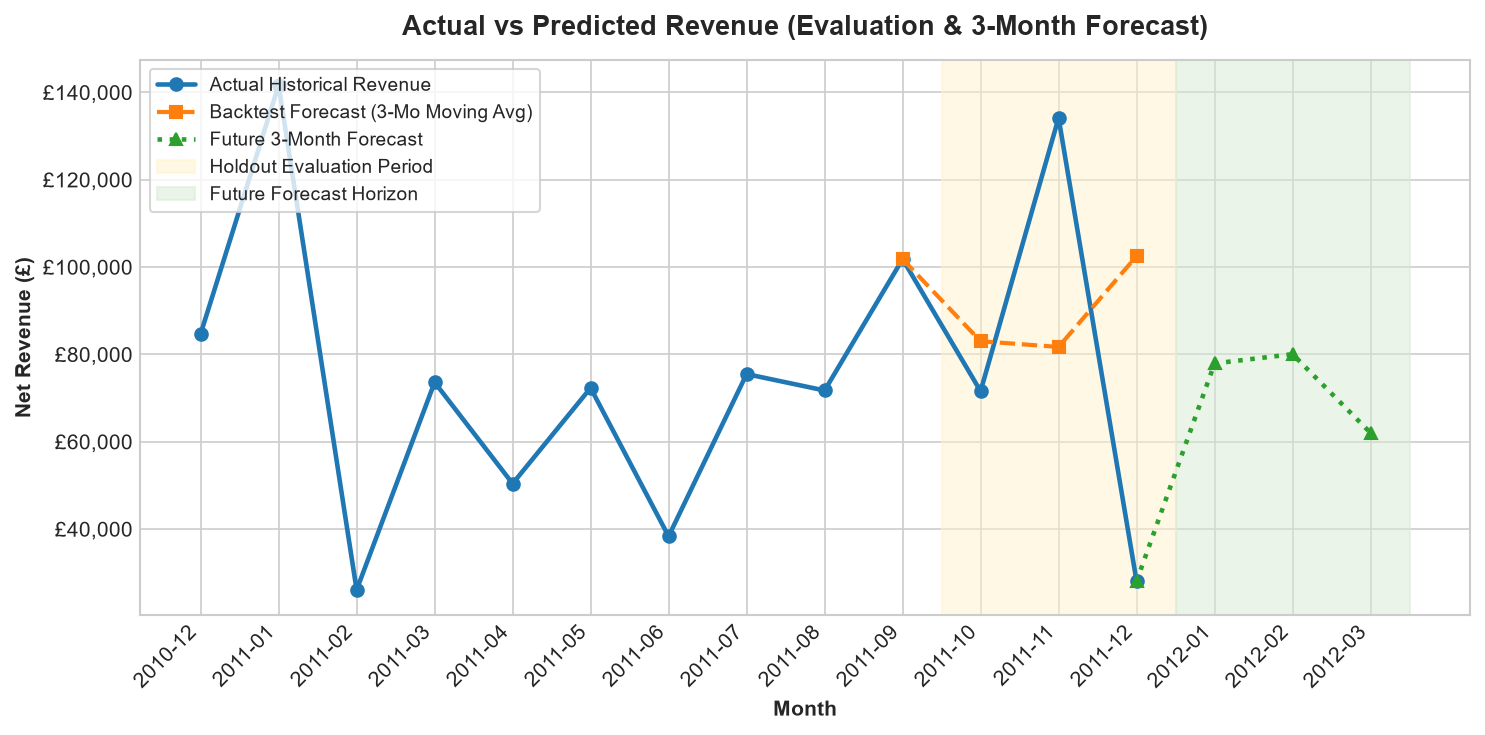

In [17]:
# Chart 6: Actual vs Predicted Revenue
fig, ax = plt.subplots(figsize=(10, 5), dpi=150)
full_months = list(hist_monthly['Month']) + future_names
actual_curve = list(hist_monthly['Monthly_Revenue']) + [np.nan]*3

ax.plot(full_months[:total_m], actual_curve[:total_m], marker='o', color='#1f77b4', label='Actual Historical Revenue', linewidth=2.2)

# Evaluation line
eval_x = [full_months[total_m - holdout_w - 1]] + list(eval_df['Month'])
eval_y = [actual_curve[total_m - holdout_w - 1]] + list(eval_df['Predicted_Revenue'])
ax.plot(eval_x, eval_y, marker='s', linestyle='--', color='#ff7f0e', label='Backtest Forecast (3-Mo Moving Avg)', linewidth=2.0)

# Future forecast line
future_x = [full_months[total_m - 1]] + future_names
future_y = [actual_curve[total_m - 1]] + list(future_df['Predicted_Revenue'])
ax.plot(future_x, future_y, marker='^', linestyle=':', color='#2ca02c', label='Future 3-Month Forecast', linewidth=2.2)

ax.axvspan(total_m - holdout_w - 0.5, total_m - 0.5, color='#fff2cc', alpha=0.5, label='Holdout Evaluation Period')
ax.axvspan(total_m - 0.5, len(full_months) - 0.5, color='#d9ead3', alpha=0.5, label='Future Forecast Horizon')

ax.set_title('Actual vs Predicted Revenue (Evaluation & 3-Month Forecast)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Month', fontsize=10, fontweight='bold')
ax.set_ylabel('Net Revenue (£)', fontsize=10, fontweight='bold')
ax.set_xticks(range(len(full_months)))
ax.set_xticklabels(full_months, rotation=45, ha='right')
ax.yaxis.set_major_formatter('£{x:,.0f}')
ax.legend(loc='upper left', frameon=True, fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join('..', 'outputs', 'charts', '06_actual_vs_predicted_revenue.png'))
plt.show()

### Limitations of Basic Moving Average Forecasting
While simple moving averages provide an intuitive baseline, several critical analytical limitations exist in retail contexts:
1. **Inability to Model Seasonality**: Retail exhibits strong holiday surges (e.g., November pre-Christmas volume of £134k). The moving average produced a 39.1% error in November because it only smoothed preceding autumn months.
2. **Lagging Indicator**: Moving averages cannot anticipate trend reversals, systematically lagging behind demand acceleration or contraction.
3. **Sensitivity to Incomplete Time Windows**: December 2011 truncated on December 9th (£28k actual revenue), but the 3-month moving average projected £102.5k based on preceding peak months, resulting in a 265.2% error.
4. **Lack of Exogenous Features**: The model assumes sales depend solely on past sales, ignoring pricing promotions, marketing spend, macroeconomic shifts, and stock availability.

## 11. Final Observations

### Summary of Key Findings:
1. **Revenue Concentration**:
   - The top customer segment (**Champions**) generates **58.4% of total customer revenue** (£484.0k) with a 100% repeat purchase rate and £585 average revenue.
   - The **UK home market** accounts for **85.0% of total revenue** (£824.5k), followed by Netherlands (2.6%), EIRE (2.5%), France (2.3%), and Germany (2.0%).
2. **Lapsed Customer Value**:
   - The **At Risk** segment represents 817 high-value past customers who contributed **23.6% of historical revenue** (£195.5k) but have lapsed.
3. **Data Integrity & Reconciliation**:
   - Reconciled £970,447.76 raw revenue down to £970,157.61 cleaned net revenue with exact £0.00 discrepancy, accounting for 52 duplicates (£290.15) and £48,093.73 in return offsets.

### Practical Recommendations:
1. **VIP Retention & Exclusive Benefits**: Implement automated VIP loyalty tiers and dedicated account management for Champions to protect the 58.4% revenue base.
2. **Win-Back Campaigns for At-Risk Customers**: Launch targeted, personalized reactivation promotions for the 817 At-Risk customers before customer equity fully erodes.
3. **International Expansion Strategy**: Strengthen logistics and localized marketing in Northern European hubs (Netherlands, Germany, France) to diversify beyond the 85% UK concentration.